In [ ]:
import os

print(os.listdir("/content"))


['.config', 'archive.zip', 'sample_data']


In [ ]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/flight_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print(os.listdir(extract_path))

Extraction completed!
['Clean_Dataset.csv', 'business.csv', 'economy.csv']


In [ ]:
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

/content/flight_dataset/Clean_Dataset.csv
/content/flight_dataset/business.csv
/content/flight_dataset/economy.csv


In [ ]:
import pandas as pd

df = pd.read_csv("/content/flight_dataset/Clean_Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (300153, 12)


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

Column names:
['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int6

In [ ]:
# Display summary statistics for numerical columns
df.describe()

,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [ ]:
print(df["Unnamed: 0"].head(10).tolist())
print("Number of unique values:", df["Unnamed: 0"].nunique())


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Number of unique values: 300153


In [ ]:
df.drop(columns=["Unnamed: 0"], inplace=True)

print("Updated dataset shape:", df.shape)
print(df.columns.tolist())

Updated dataset shape: (300153, 11)
['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
numerical_columns = df.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

Numerical columns: ['duration', 'days_left', 'price']
Categorical columns: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print("Minimum ticket price:", df["price"].min())
print("Maximum ticket price:", df["price"].max())
print("Average ticket price:", round(df["price"].mean(), 2))
print("Median ticket price:", df["price"].median())
print("Standard deviation:", round(df["price"].std(), 2))

Minimum ticket price: 1105
Maximum ticket price: 123071
Average ticket price: 20889.66
Median ticket price: 7425.0
Standard deviation: 22697.77


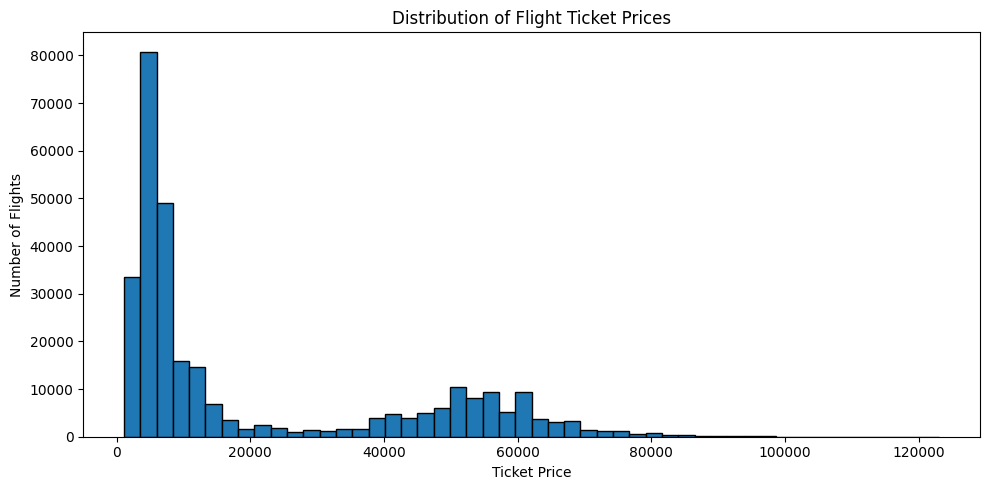

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["price"], bins=50, edgecolor="black")
plt.title("Distribution of Flight Ticket Prices")
plt.xlabel("Ticket Price")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

In [ ]:
print(df.groupby("class")["price"].describe().round(2))

             count      mean       std      min      25%      50%      75%  \
class                                                                        
Business   93487.0  52540.08  12969.31  12000.0  45185.0  53164.0  60396.0   
Economy   206666.0   6572.34   3743.52   1105.0   4173.0   5772.0   7746.0   

               max  
class               
Business  123071.0  
Economy    42349.0  


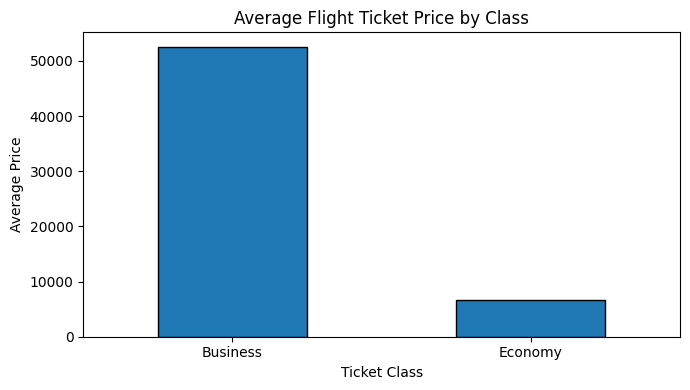

In [ ]:
class_prices = df.groupby("class")["price"].mean()

class_prices.plot(kind="bar", figsize=(7, 4), edgecolor="black")

plt.title("Average Flight Ticket Price by Class")
plt.xlabel("Ticket Class")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
airline_prices = (
    df.groupby("airline")["price"]
    .agg(["mean", "median", "count"])
    .round(2)
    .sort_values("mean", ascending=False)
)

print(airline_prices)

               mean   median   count
airline                             
Vistara    30396.54  15543.0  127859
Air_India  23507.02  11520.0   80892
SpiceJet    6179.28   5654.0    9011
GO_FIRST    5652.01   5336.0   23173
Indigo      5324.22   4453.0   43120
AirAsia     4091.07   3276.0   16098


In [ ]:
print(df.groupby("class")["price"].describe().round(2))

             count      mean       std      min      25%      50%      75%  \
class                                                                        
Business   93487.0  52540.08  12969.31  12000.0  45185.0  53164.0  60396.0   
Economy   206666.0   6572.34   3743.52   1105.0   4173.0   5772.0   7746.0   

               max  
class               
Business  123071.0  
Economy    42349.0  


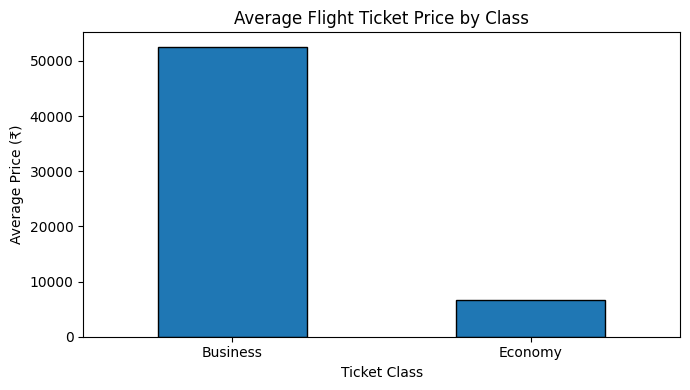

In [ ]:
class_prices = df.groupby("class")["price"].mean()

plt.figure(figsize=(7, 4))
class_prices.plot(kind="bar", edgecolor="black")

plt.title("Average Flight Ticket Price by Class")
plt.xlabel("Ticket Class")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
booking_prices = (
    df.groupby("days_left")["price"]
    .mean()
    .reset_index()
)

print(booking_prices.head(10))

   days_left         price
0          1  21591.867151
1          2  30211.299801
2          3  28976.083569
3          4  25730.905653
4          5  26679.773368
5          6  24856.493902
6          7  25588.367351
7          8  24895.883995
8          9  25726.246072
9         10  25572.819134


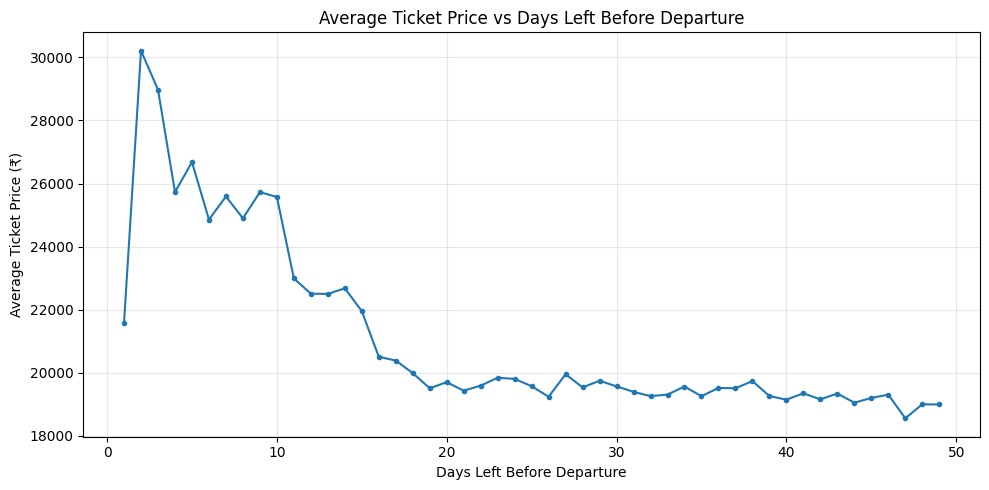

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    booking_prices["days_left"],
    booking_prices["price"],
    marker="o",
    markersize=3
)

plt.title("Average Ticket Price vs Days Left Before Departure")
plt.xlabel("Days Left Before Departure")
plt.ylabel("Average Ticket Price (₹)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print(booking_prices.to_string(index=False))

 days_left        price
         1 21591.867151
         2 30211.299801
         3 28976.083569
         4 25730.905653
         5 26679.773368
         6 24856.493902
         7 25588.367351
         8 24895.883995
         9 25726.246072
        10 25572.819134
        11 22990.656070
        12 22505.803322
        13 22498.885384
        14 22678.002363
        15 21952.540852
        16 20503.546237
        17 20386.353949
        18 19987.445168
        19 19507.677375
        20 19699.983390
        21 19430.494058
        22 19590.667385
        23 19840.913451
        24 19803.908896
        25 19571.641791
        26 19238.290278
        27 19950.866195
        28 19534.986047
        29 19744.653119
        30 19567.580834
        31 19392.706612
        32 19258.135308
        33 19306.271739
        34 19562.008266
        35 19255.652996
        36 19517.688444
        37 19506.306516
        38 19734.912316
        39 19262.095556
        40 19144.972439
        41 19347

In [ ]:
print(booking_prices.head(10))
print("\nLast 10 values:")
print(booking_prices.tail(10))

   days_left         price
0          1  21591.867151
1          2  30211.299801
2          3  28976.083569
3          4  25730.905653
4          5  26679.773368
5          6  24856.493902
6          7  25588.367351
7          8  24895.883995
8          9  25726.246072
9         10  25572.819134

Last 10 values:
    days_left         price
39         40  19144.972439
40         41  19347.440460
41         42  19154.261659
42         43  19340.528894
43         44  19049.080174
44         45  19199.876307
45         46  19305.351623
46         47  18553.272038
47         48  18998.126851
48         49  18992.971888


In [ ]:
airline_class_prices = (
    df.groupby(["airline", "class"])["price"]
    .mean()
    .unstack()
    .round(2)
)

print(airline_class_prices)

class      Business  Economy
airline                     
AirAsia         NaN  4091.07
Air_India  47131.04  7313.68
GO_FIRST        NaN  5652.01
Indigo          NaN  5324.22
SpiceJet        NaN  6179.28
Vistara    55477.03  7806.94


In [ ]:
df["route"] = df["source_city"] + " to " + df["destination_city"]

print(df["route"].value_counts().head(10))

route
Delhi to Mumbai        15289
Mumbai to Delhi        14809
Delhi to Bangalore     14012
Bangalore to Delhi     13756
Bangalore to Mumbai    12939
Mumbai to Bangalore    12885
Mumbai to Kolkata      12602
Delhi to Kolkata       11934
Kolkata to Mumbai      11467
Delhi to Chennai       10780
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt

top_routes = df["route"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_routes.sort_values().plot(kind="barh")

plt.title("Top 10 Most Frequent Flight Routes")
plt.xlabel("Number of Records")
plt.ylabel("Route")
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

In [ ]:
import pandas as pd

df = pd.read_csv("/content/flight_dataset/Clean_Dataset.csv")

# Remove the unnecessary index column again
df.drop(columns=["Unnamed: 0"], inplace=True, errors="ignore")

# Recreate the route column
df["route"] = df["source_city"] + " to " + df["destination_city"]

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/flight_dataset/Clean_Dataset.csv'

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
import zipfile
import os

zip_path = "archiev.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/flight_dataset")

print(os.listdir("/content/flight_dataset"))

FileNotFoundError: [Errno 2] No such file or directory: 'archiev.zip'

In [ ]:
import os

print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'sample_data']


In [ ]:
import os

print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'archive.zip', 'sample_data']


In [ ]:
import os
import zipfile
import pandas as pd

# Find ZIP files uploaded to Colab
zip_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".zip")
]

print("ZIP files found:", zip_files)

# Extract the uploaded ZIP
if not zip_files:
    print("No ZIP file found. Please upload it again.")
else:
    zip_path = os.path.join("/content", zip_files[0])
    extract_path = "/content/flight_dataset"
    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    # Locate Clean_Dataset.csv, including in subfolders
    csv_path = None

    for root, dirs, files in os.walk(extract_path):
        if "Clean_Dataset.csv" in files:
            csv_path = os.path.join(root, "Clean_Dataset.csv")
            break

    if csv_path:
        df = pd.read_csv(csv_path)
        df.drop(columns=["Unnamed: 0"], inplace=True, errors="ignore")
        df["route"] = df["source_city"] + " to " + df["destination_city"]

        print("\nDataset restored successfully!")
        print("Shape:", df.shape)
        print("\nFirst five rows:")
        display(df.head())
    else:
        print("Clean_Dataset.csv was not found. Check the extracted file list.")

ZIP files found: ['archive.zip']

Dataset restored successfully!
Shape: (300153, 12)

First five rows:


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,route
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953,Delhi to Mumbai
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953,Delhi to Mumbai
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956,Delhi to Mumbai
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955,Delhi to Mumbai
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955,Delhi to Mumbai


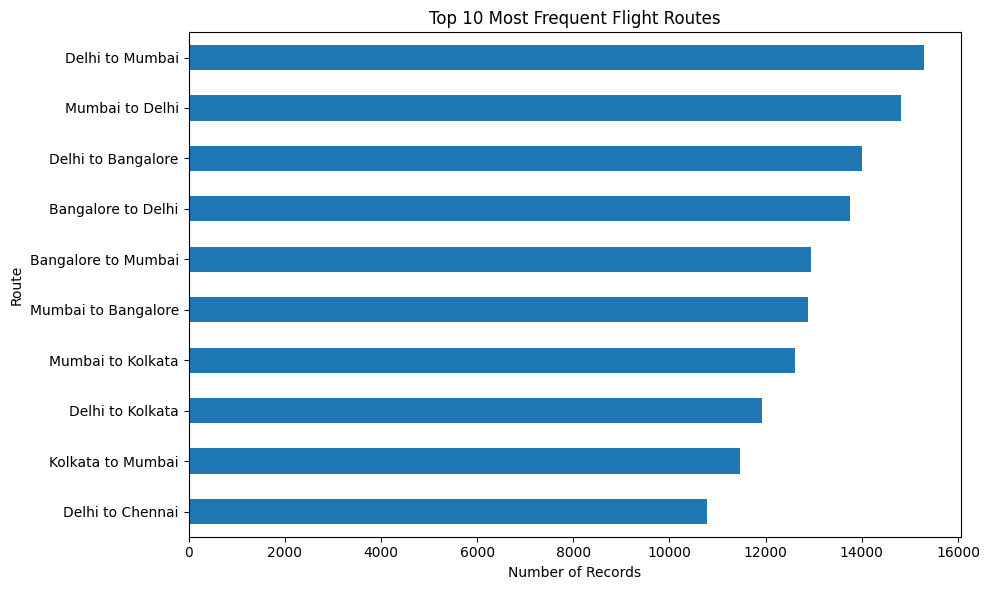

In [ ]:
import matplotlib.pyplot as plt

top_routes = df["route"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_routes.sort_values().plot(kind="barh")

plt.title("Top 10 Most Frequent Flight Routes")
plt.xlabel("Number of Records")
plt.ylabel("Route")
plt.tight_layout()
plt.show()

In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
route               0
dtype: int64


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
stops_analysis = (
    df.groupby("stops")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean")
)

print(stops_analysis)

              count      mean  median
stops                                
zero          36004   9375.94  4499.0
two_or_more   13286  14113.45  8307.0
one          250863  22900.99  7959.0


In [ ]:
departure_analysis = (
    df.groupby("departure_time")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean")
)

print(departure_analysis)

                count      mean  median
departure_time                         
Late_Night       1306   9295.30  4499.0
Afternoon       47794  18179.20  6663.0
Early_Morning   66790  20370.68  7212.0
Evening         65102  21232.36  7425.0
Morning         71146  21630.76  8112.0
Night           48015  23062.15  7813.0


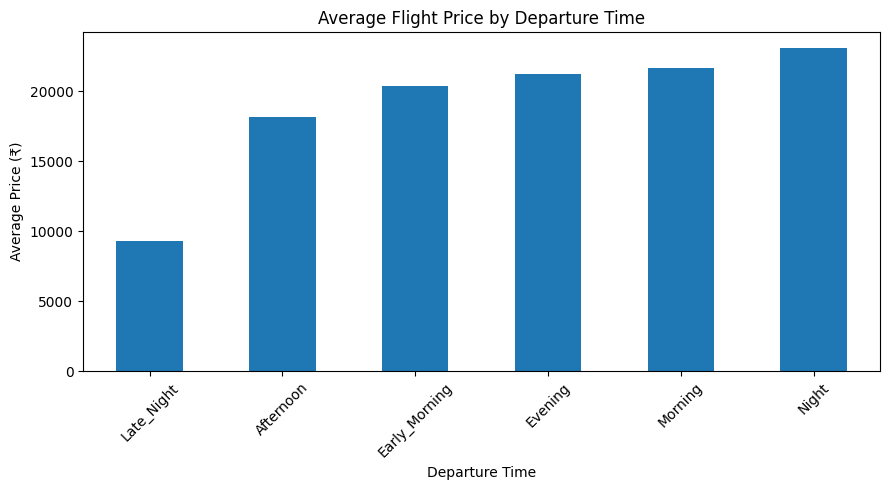

In [ ]:
import matplotlib.pyplot as plt

departure_prices = df.groupby("departure_time")["price"].mean().sort_values()

plt.figure(figsize=(9, 5))
departure_prices.plot(kind="bar")

plt.title("Average Flight Price by Departure Time")
plt.xlabel("Departure Time")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
arrival_analysis = (
    df.groupby("arrival_time")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean")
)

print(arrival_analysis)

               count      mean  median
arrival_time                          
Late_Night     14001  11284.91  4867.0
Early_Morning  15417  14993.14  5800.0
Afternoon      38139  18494.60  6714.0
Night          91538  21586.76  7584.0
Morning        62735  22231.08  7687.0
Evening        78323  23044.37  8854.0


In [ ]:
arrival_analysis = (
    df.groupby("arrival_time")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean")
)

print(arrival_analysis)

               count      mean  median
arrival_time                          
Late_Night     14001  11284.91  4867.0
Early_Morning  15417  14993.14  5800.0
Afternoon      38139  18494.60  6714.0
Night          91538  21586.76  7584.0
Morning        62735  22231.08  7687.0
Evening        78323  23044.37  8854.0


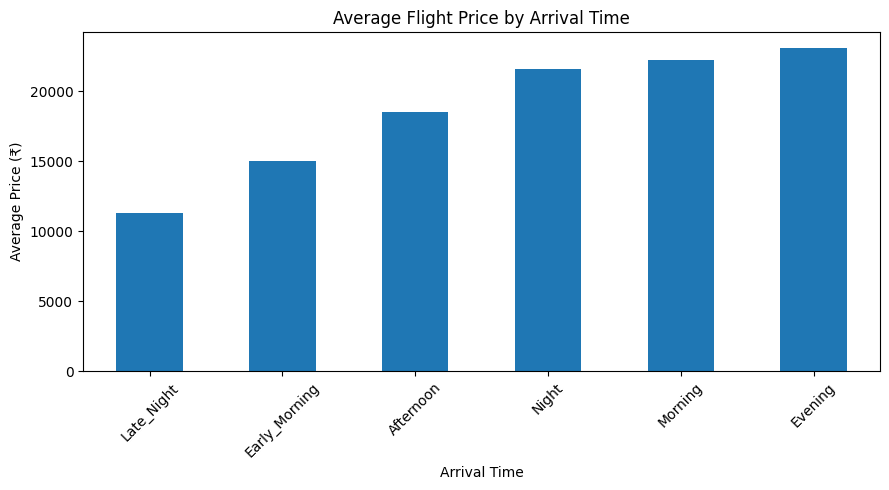

In [ ]:
arrival_prices = (
    df.groupby("arrival_time")["price"]
    .mean()
    .sort_values()
)

arrival_prices.plot(kind="bar", figsize=(9, 5))
plt.title("Average Flight Price by Arrival Time")
plt.xlabel("Arrival Time")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
print("Duration summary:")
print(df["duration"].describe().round(2))

duration_groups = pd.cut(
    df["duration"],
    bins=[0, 2, 4, 6, 8, 12, float("inf")],
    labels=["0–2", "2–4", "4–6", "6–8", "8–12", "12+"],
    right=False
)

print("\nAverage price by duration group:")
print(
    df.groupby(duration_groups, observed=True)["price"]
    .agg(["count", "mean", "median"])
    .round(2)
)

Duration summary:
count    300153.00
mean         12.22
std           7.19
min           0.83
25%           6.83
50%          11.25
75%          16.17
max          49.83
Name: duration, dtype: float64

Average price by duration group:
           count      mean   median
duration                           
0–2         9463   5555.49   2901.0
2–4        28162  10535.06   4502.0
4–6        22083  13401.84   5632.0
6–8        34826  16888.26   6299.0
8–12       67170  21043.43   7462.0
12+       138449  26170.24  11205.0


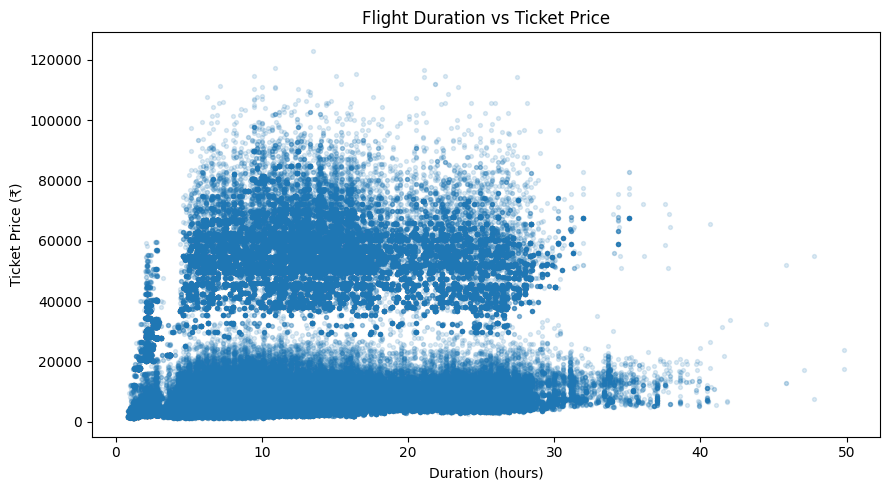

In [ ]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["duration"],
    df["price"],
    alpha=0.15,
    s=8
)

plt.title("Flight Duration vs Ticket Price")
plt.xlabel("Duration (hours)")
plt.ylabel("Ticket Price (₹)")
plt.tight_layout()
plt.show()

In [ ]:
source_analysis = (
    df.groupby("source_city")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean")
)

print(source_analysis)

             count      mean  median
source_city                         
Delhi        61343  18951.33  6840.0
Hyderabad    40806  20155.62  6855.0
Bangalore    52061  21469.46  7488.0
Mumbai       60896  21483.82  7413.0
Kolkata      46347  21746.24  7958.0
Chennai      38700  21995.34  7846.0


In [ ]:
destination_analysis = (
    df.groupby("destination_city")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean")
)

print(destination_analysis)

                  count      mean  median
destination_city                         
Delhi             57360  18436.77  6521.0
Hyderabad         42726  20427.66  7548.0
Mumbai            59097  21372.53  7496.0
Bangalore         51068  21593.96  7425.0
Chennai           40368  21953.32  7900.0
Kolkata           49534  21959.56  7767.0


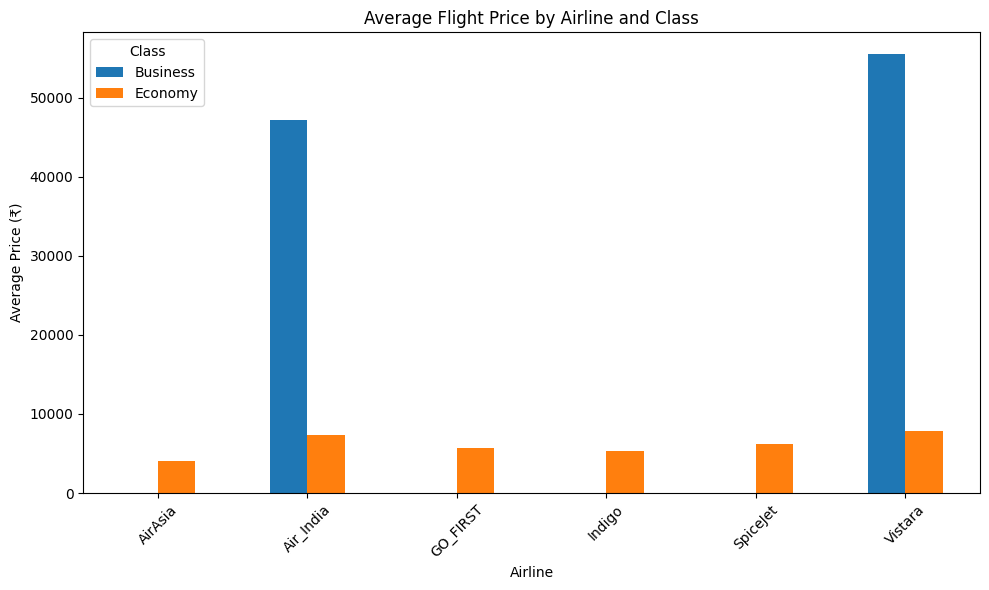

In [ ]:
airline_class_prices = (
    df.groupby(["airline", "class"])["price"]
    .mean()
    .unstack()
)

airline_class_prices.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Flight Price by Airline and Class")
plt.xlabel("Airline")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45)
plt.legend(title="Class")
plt.tight_layout()
plt.show()

In [ ]:
top_10_routes = df["route"].value_counts().head(10).index

route_analysis = (
    df[df["route"].isin(top_10_routes)]
    .groupby("route")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean")
)

print(route_analysis)

                     count      mean  median
route                                       
Bangalore to Delhi   13756  17723.31  7164.0
Delhi to Bangalore   14012  17880.22  6642.0
Mumbai to Delhi      14809  18725.32  6300.0
Delhi to Mumbai      15289  19355.83  7262.0
Delhi to Chennai     10780  19369.88  7425.0
Delhi to Kolkata     11934  20566.41  7084.0
Kolkata to Mumbai    11467  22078.88  7958.0
Mumbai to Kolkata    12602  22379.15  7518.0
Bangalore to Mumbai  12939  23128.62  7113.0
Mumbai to Bangalore  12885  23147.87  7192.0


In [ ]:
numerical_columns = ["duration", "days_left", "price"]

correlation = df[numerical_columns].corr()

print(correlation.round(3))

           duration  days_left  price
duration      1.000     -0.039  0.204
days_left    -0.039      1.000 -0.092
price         0.204     -0.092  1.000


In [4]:
plt.figure(figsize=(7, 5))

plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)
plt.yticks(
    range(len(correlation.index)),
    correlation.index
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Separate input features and target
X = df.drop(columns=["price", "flight", "route"])
y = df["price"]

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']
Numerical features: ['duration', 'days_left']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 240122
Testing records: 60031


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_transformer, categorical_features),
    ("numerical", numerical_transformer, numerical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R² Score:", round(r2, 4))

Mean Absolute Error: 1077.41
Root Mean Squared Error: 2787.06
R² Score: 0.9849


In [3]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, predictions, alpha=0.2, s=8)

plt.title("Actual vs Predicted Flight Prices")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [5]:
print("plt exists:", "plt" in globals())
print("y_test exists:", "y_test" in globals())
print("predictions exists:", "predictions" in globals())
print("model exists:", "model" in globals())

plt exists: False
y_test exists: False
predictions exists: False
model exists: False


In [6]:
plt.figure(figsize=(7, 5))

plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)
plt.yticks(
    range(len(correlation.index)),
    correlation.index
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [7]:
import matplotlib.pyplot as plt

In [8]:
plt.figure(figsize=(7, 5))

plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.index)), correlation.index)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

NameError: name 'correlation' is not defined

<Figure size 700x500 with 0 Axes>

In [9]:
correlation = df[["duration", "days_left", "price"]].corr()

print(correlation)

NameError: name 'df' is not defined

In [10]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".zip") or file == "Clean_Dataset.csv":
            print(os.path.join(root, file))

/content/archive.zip


In [11]:
import zipfile
import os
import pandas as pd

zip_path = "/content/archive.zip"
extract_path = "/content/flight_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Locate the CSV file
csv_path = None

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file == "Clean_Dataset.csv":
            csv_path = os.path.join(root, file)
            break
    if csv_path:
        break

if csv_path:
    df = pd.read_csv(csv_path)
    df.drop(columns=["Unnamed: 0"], errors="ignore", inplace=True)
    df["route"] = df["source_city"] + " to " + df["destination_city"]

    print("Dataset restored successfully!")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
else:
    print("Clean_Dataset.csv was not found in the ZIP.")

Dataset restored successfully!
Shape: (300153, 12)
Columns: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price', 'route']


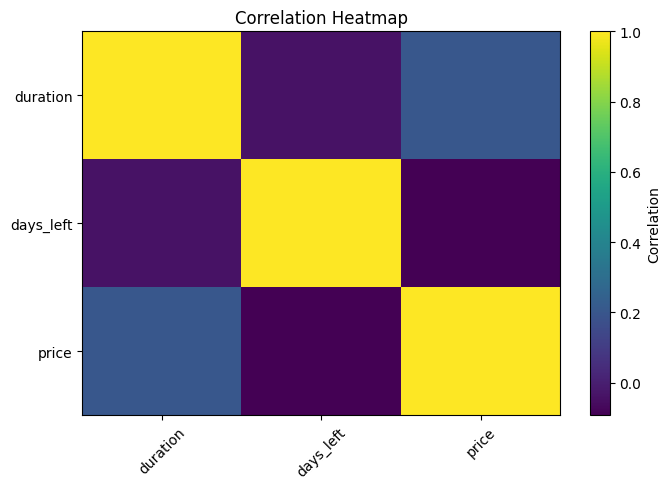

In [12]:
import matplotlib.pyplot as plt

correlation = df[["duration", "days_left", "price"]].corr()

plt.figure(figsize=(7, 5))
plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.index)), correlation.index)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [13]:
print("Model:", "model" in globals())
print("X_test:", "X_test" in globals())
print("y_test:", "y_test" in globals())
print("Predictions:", "predictions" in globals())

Model: False
X_test: False
y_test: False
Predictions: False


In [14]:
# Separate input features and target
X = df.drop(columns=["price", "flight", "route"])
y = df["price"]

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("X shape:", X.shape)
print("y shape:", y.shape)

Categorical features: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']
Numerical features: ['duration', 'days_left']
X shape: (300153, 9)
y shape: (300153,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (240122, 9)
Testing data: (60031, 9)


In [16]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocess numerical features
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_transformer, categorical_features),
    ("numerical", numerical_transformer, numerical_features)
])

# Create the prediction pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))

Mean Absolute Error (MAE): 1077.41
Root Mean Squared Error (RMSE): 2787.06
R² Score: 0.9849


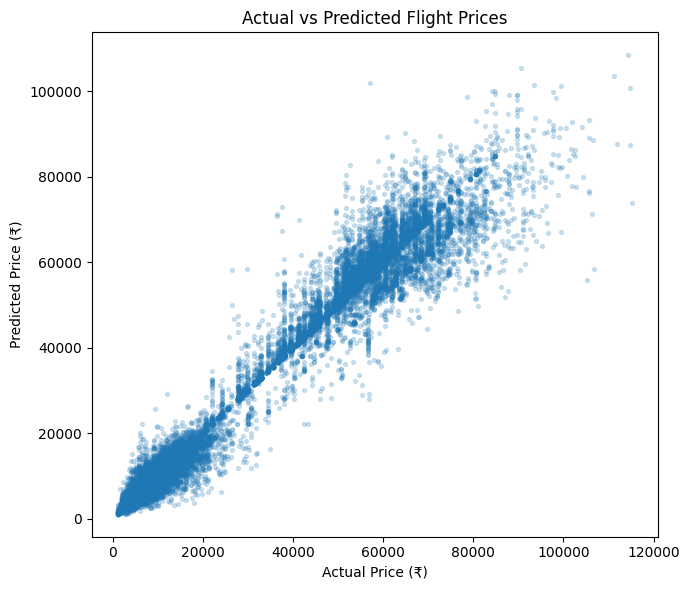

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(y_test, predictions, alpha=0.2, s=8)
plt.title("Actual vs Predicted Flight Prices")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.tight_layout()
plt.show()

In [19]:
import pandas as pd

results = pd.DataFrame({
    "Metric": ["Mean Absolute Error", "Root Mean Squared Error", "R² Score"],
    "Value": [mae, rmse, r2]
})

print(results)

                    Metric        Value
0      Mean Absolute Error  1077.406924
1  Root Mean Squared Error  2787.061613
2                 R² Score     0.984931


                                    Feature  Importance
33              categorical__class_Business    0.448757
34               categorical__class_Economy    0.431099
35                      numerical__duration    0.057787
36                     numerical__days_left    0.018507
1            categorical__airline_Air_India    0.005867
5              categorical__airline_Vistara    0.004095
8            categorical__source_city_Delhi    0.003807
29      categorical__destination_city_Delhi    0.003466
11          categorical__source_city_Mumbai    0.002281
32     categorical__destination_city_Mumbai    0.001870
31    categorical__destination_city_Kolkata    0.001787
10         categorical__source_city_Kolkata    0.001690
30  categorical__destination_city_Hyderabad    0.001522
23        categorical__arrival_time_Evening    0.001514
27  categorical__destination_city_Bangalore    0.001272


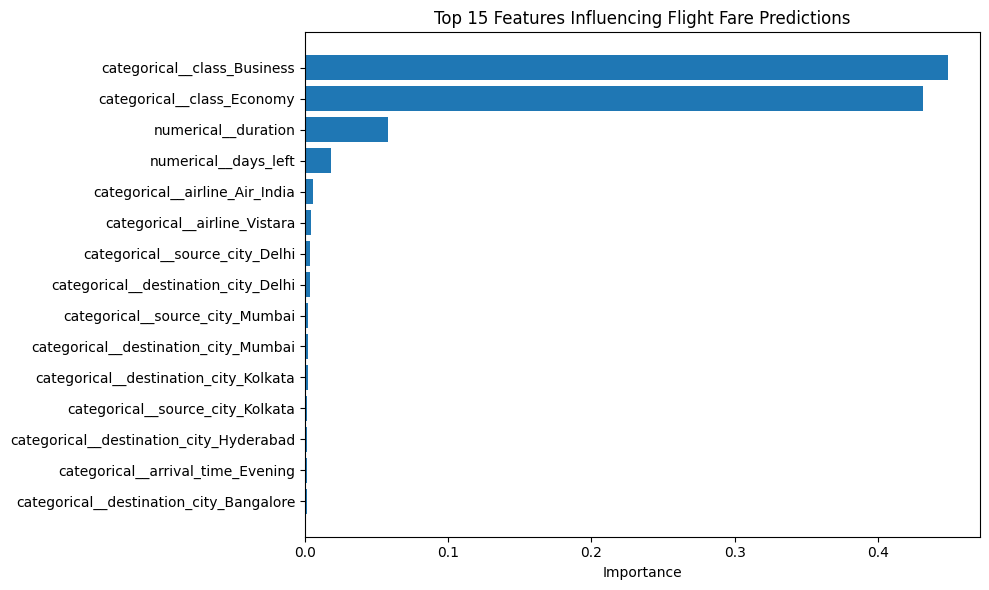

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance from the trained Random Forest
importances = model.named_steps["regressor"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(feature_importance.head(15))

# Plot the top 15 features
top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.title("Top 15 Features Influencing Flight Fare Predictions")
plt.tight_layout()
plt.show()

In [21]:
import joblib

joblib.dump(model, "flight_fare_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [1]:
from google.colab import files

files.download("flight_fare_model.pkl")

FileNotFoundError: Cannot find file: flight_fare_model.pkl

In [2]:
import os

print("Model file exists:", os.path.exists("/content/flight_fare_model.pkl"))
print("Current directory:", os.getcwd())

Model file exists: False
Current directory: /content


In [3]:
import joblib

joblib.dump(model, "/content/flight_fare_model.pkl")

print("Model saved successfully!")

NameError: name 'model' is not defined

In [4]:
print("Model available:", "model" in globals())

Model available: False


In [5]:
import os
import zipfile
import pandas as pd

zip_path = "/content/archive.zip"
extract_path = "/content/flight_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

csv_path = None

for root, dirs, files in os.walk(extract_path):
    if "Clean_Dataset.csv" in files:
        csv_path = os.path.join(root, "Clean_Dataset.csv")
        break

if csv_path:
    df = pd.read_csv(csv_path)
    df.drop(columns=["Unnamed: 0"], errors="ignore", inplace=True)
    df["route"] = df["source_city"] + " to " + df["destination_city"]
    print("Dataset restored:", df.shape)
else:
    print("CSV not found. Please share the output.")

Dataset restored: (300153, 12)


In [6]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["price", "flight", "route"])
y = df["price"]

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training and testing data prepared.")

Training and testing data prepared.


In [7]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_transformer, categorical_features),
    ("numerical", numerical_transformer, numerical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=30,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=2
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [8]:
import joblib

model_path = "/content/flight_fare_model.pkl"
joblib.dump(model, model_path)

print("Saved:", os.path.exists(model_path))

Saved: True


In [9]:
from google.colab import files
files.download("/content/flight_fare_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import os
import joblib

model_path = "/content/flight_fare_model.pkl"

print("Model file exists:", os.path.exists(model_path))

Model file exists: True


In [11]:
saved_model = joblib.load(model_path)
print("Saved model loaded successfully!")

Saved model loaded successfully!


In [12]:
sample = X_test.iloc[[0]]
actual_price = y_test.iloc[0]

predicted_price = saved_model.predict(sample)[0]

print("Actual flight price: ₹", round(actual_price, 2))
print("Predicted flight price: ₹", round(predicted_price, 2))

Actual flight price: ₹ 7366
Predicted flight price: ₹ 7325.97


In [13]:
import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R² Score"
    ],
    "Value": [mae, rmse, r2]
})

results.to_csv("/content/model_evaluation_results.csv", index=False)

print(results)
print("\nEvaluation results saved successfully!")

NameError: name 'mae' is not defined

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

MAE: 1304.33
RMSE: 2817.59
R² Score: 0.9846


In [15]:
import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R² Score"
    ],
    "Value": [mae, rmse, r2]
})

results.to_csv("/content/model_evaluation_results.csv", index=False)

print(results)
print("Evaluation results saved!")

                           Metric        Value
0       Mean Absolute Error (MAE)  1304.334392
1  Root Mean Squared Error (RMSE)  2817.587534
2                        R² Score     0.984599
Evaluation results saved!


In [16]:
from google.colab import files

files.download("/content/model_evaluation_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>